# 모듈 1. EDGAR 데이터 수집

**목표**
1. JPM 구조화 노트 발행사의 공시 목록을 가져와 발행 추이를 파악한다.
2. 전문 검색(Full-Text Search)으로 상품 유형별 발행량을 가늠한다.
3. 분석용 표본을 뽑아 원문을 내려받고 평문으로 변환해 저장한다.

**산출물**: `data/raw/*.htm` (원문), `data/interim/filings_sample.parquet` (메타데이터 + 평문)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

from aifinance import EdgarClient, JPM_FINANCIAL_CIK, html_to_text
from aifinance.config import INTERIM_DIR
from aifinance.plotting import setup_korean_font

setup_korean_font()
pd.set_option("display.max_colwidth", 120)
client = EdgarClient()

## 1. 공시 목록

`data.sec.gov/submissions` API는 회사별 공시 목록을 JSON으로 줍니다.
`recent` 블록에는 최근 약 1년치가 들어 있고, 더 오래된 공시는 `include_older=True`로 가져옵니다(요청 수십 번).

In [2]:
filings = client.list_filings(JPM_FINANCIAL_CIK)
print(f"{len(filings):,}건  ({filings.filingDate.min():%Y-%m-%d} ~ {filings.filingDate.max():%Y-%m-%d})")
filings.form.value_counts()

25,192건  (2025-11-10 ~ 2026-11-10)


form
424B2      22093
FWP         1800
424B3       1258
424B8         36
EFFECT         1
S-3/A          1
CORRESP        1
UPLOAD         1
S-3            1
Name: count, dtype: int64

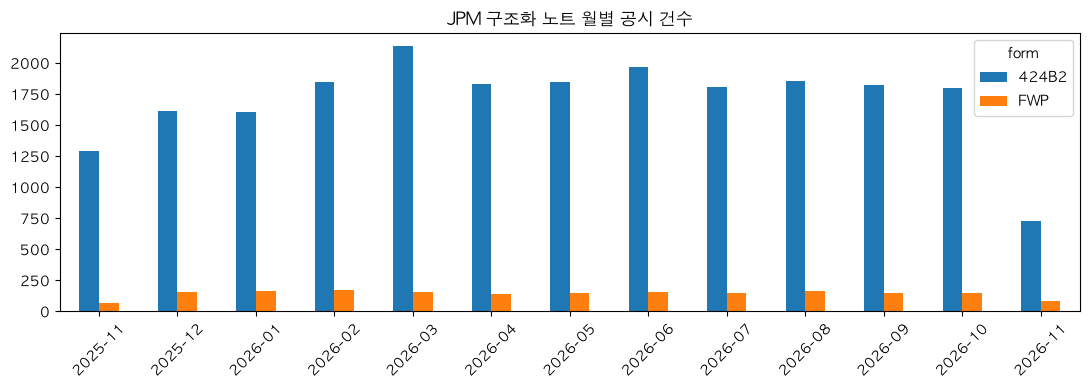

In [3]:
monthly = (
    filings[filings.form.isin(["424B2", "FWP"])]
    .groupby([pd.Grouper(key="filingDate", freq="MS"), "form"])
    .size()
    .unstack(fill_value=0)
)
monthly.index = monthly.index.strftime("%Y-%m")
ax = monthly.plot(kind="bar", figsize=(11, 4), rot=45, title="JPM 구조화 노트 월별 공시 건수")
ax.set_xlabel("")
plt.tight_layout()

> **생각해 볼 점**: 한 달에 1,500건이 넘는 424B2. 대부분은 소액(수십만 달러) 맞춤형 발행입니다.
> 발행 건수와 발행 금액 중 무엇이 상품 전략을 더 잘 보여 줄까요? (금액은 모듈 2에서 추출합니다.)

## 2. 전문 검색으로 상품 유형 가늠하기

`efts.sec.gov` 전문 검색은 공시 본문에서 키워드를 찾습니다. 최근 1개월간 상품명 키워드별 424B2 건수를 세어 봅니다.
(한 문서에 키워드가 여러 개 나올 수 있으므로 **합계가 전체와 맞지 않는 것이 정상**입니다.)

원금보장(Principal Protected)        0
Trigger PLUS                     9
디지털(Digital)                   233
Worst Of(Least Performing)     414
버퍼(Buffered)                   485
조건부 쿠폰(Contingent Interest)    561
오토콜(Auto Callable)             695
dtype: int64

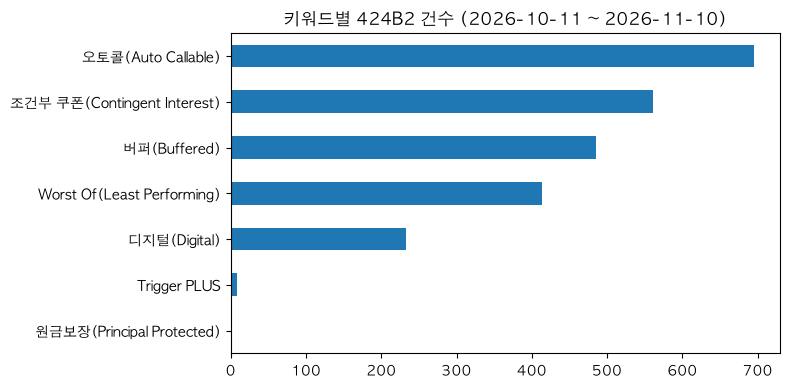

In [4]:
end = filings.filingDate.max()
start = end - pd.Timedelta(days=30)
keywords = {
    "오토콜(Auto Callable)": '"Auto Callable"',
    "조건부 쿠폰(Contingent Interest)": '"Contingent Interest"',
    "버퍼(Buffered)": '"Buffered"',
    "Trigger PLUS": '"Trigger PLUS"',
    "디지털(Digital)": '"Digital"',
    "원금보장(Principal Protected)": '"Principal Protected"',
    "Worst Of(Least Performing)": '"Least Performing"',
}
counts = {}
for label, q in keywords.items():
    total, _ = client.full_text_search(q, start=f"{start:%Y-%m-%d}", end=f"{end:%Y-%m-%d}", cik=JPM_FINANCIAL_CIK)
    counts[label] = total
counts = pd.Series(counts).sort_values()
counts.plot(kind="barh", figsize=(8, 4), title=f"키워드별 424B2 건수 ({start:%Y-%m-%d} ~ {end:%Y-%m-%d})")
plt.tight_layout()
counts

## 3. 분석용 표본 추출

전량(연 2만 건)을 수업에서 다루기는 무겁습니다. 기준일 이전 90일의 424B2에서 무작위로 `SAMPLE_SIZE`건을 뽑습니다.
기준일과 `random_state`를 고정해 모든 수강생이 같은 표본을 쓰게 합니다. (submissions API의 `recent` 블록은 최근 1년치이므로, 기준일이 1년 이상 지나면 `include_older=True`가 필요합니다.)

In [5]:
SAMPLE_SIZE = 300   # 연습 시 줄여도 됩니다 (300건 ≈ 1분, 약 90MB)
END_DATE = pd.Timestamp("2026-11-10")   # 기준일 고정 → 언제 실행해도 같은 표본
START_DATE = END_DATE - pd.Timedelta(days=90)

recent_424b2 = filings[(filings.form == "424B2") & filings.filingDate.between(START_DATE, END_DATE)]
sample = recent_424b2.sample(n=min(SAMPLE_SIZE, len(recent_424b2)), random_state=42).reset_index(drop=True)
print(f"모집단 {len(recent_424b2):,}건 → 표본 {len(sample)}건")

모집단 5,494건 → 표본 300건


In [6]:
paths = [client.download(url) for url in tqdm(sample.url, desc="다운로드")]
sample["raw_path"] = [str(p) for p in paths]
sample["text"] = [html_to_text(p.read_bytes()) for p in tqdm(paths, desc="평문 변환")]
sample["n_chars"] = sample.text.str.len()
sample.n_chars.describe()

다운로드:   0%|          | 0/300 [00:00<?, ?it/s]

다운로드: 100%|██████████| 300/300 [00:00<00:00, 73399.71it/s]

평문 변환:   0%|          | 0/300 [00:00<?, ?it/s]

평문 변환:   1%|          | 2/300 [00:00<00:17, 16.60it/s]

평문 변환:   2%|▏         | 5/300 [00:00<00:15, 19.29it/s]

평문 변환:   3%|▎         | 8/300 [00:00<00:12, 23.23it/s]

... (72 outputs left out)

평문 변환:  97%|█████████▋| 292/300 [00:10<00:00, 30.53it/s]

평문 변환:  99%|█████████▊| 296/300 [00:10<00:00, 30.87it/s]

평문 변환: 100%|██████████| 300/300 [00:10<00:00, 28.83it/s]

count       300.000000
mean      56771.340000
std       14247.166765
min       21138.000000
25%       46212.250000
50%       53063.000000
75%       67862.500000
max      102190.000000
Name: n_chars, dtype: float64

## 4. 데이터 품질 첫 관문: 예비 vs 확정 보충설명서

424B2라고 모두 **확정 조건**이 아닙니다. 판매 기간 중에 제출되는 **예비 보충설명서(PRELIMINARY PRICING SUPPLEMENT)**도 같은 양식으로 들어옵니다.
예비본은 쿠폰이 *"at least 8.00% per annum"*처럼 범위로 적혀 있고 발행금액이 비어 있습니다. 가격이 확정되면 같은 상품(CUSIP)의 **확정본이 별도로** 제출됩니다.

| 구분 | 쓰임 |
|---|---|
| 확정본 | 실제 발행 조건·금액 → **상품 DB의 기준 데이터** |
| 예비본 | 판매 중인 상품 파이프라인, 확정 조건과의 차이 분석 |

In [7]:
sample["is_preliminary"] = sample.text.str[:400].str.upper().str.contains("PRELIMINARY PRICING SUPPLEMENT")
sample.is_preliminary.value_counts().rename(index={True: "예비본", False: "확정본"})

is_preliminary
확정본    150
예비본    150
Name: count, dtype: int64

## 5. 상품명 뽑아 보기

표지의 상품명 줄은 대개 `… Notes/Securities … Linked to … due <만기일>` 형태입니다. 단순 규칙으로 먼저 뽑아 봅니다.
(일부러 단순하게 만든 기준선입니다. 실패 사례 개선은 실습 1-B에서 Claude와 함께 합니다.)

In [8]:
import re

TITLE_RE = re.compile(r"(Notes|Securities|PLUS|Certificates|Warrants)\b.*\bdue\b", re.I)

def guess_title(text: str) -> str | None:
    for line in text.splitlines()[:80]:
        line = line.strip()
        if 20 < len(line) < 400 and TITLE_RE.search(line):
            return line
    return None

sample["title"] = sample.text.map(guess_title)
print(f"상품명 추출 성공률: {sample.title.notna().mean():.0%}")
sample[["filingDate", "title"]].head(15)

상품명 추출 성공률: 76%


,filingDate,title
0,2026-10-13,"Contingent Income Auto-Callable Securities due October 14,"
1,2026-11-02,NaN
2,2026-10-13,NaN
3,2026-10-27,"Auto Callable Contingent Interest Notes Linked to the Common Stock of Micron Technology, Inc. due November 26, 2029"
4,2026-08-20,NaN
5,2026-09-09,"Uncapped Buffered Return Enhanced Notes Linked to the S&P 500® Futures Excess Return Index due September 9, 2031"
6,2026-11-03,Capped Dual Directional Buffered Return Enhanced Notes Linked to the Lesser Performing of the Nasdaq-100 Index® and ...
7,2026-08-19,"$1,746,000 Market Linked Securities — Auto-Callable with Contingent Coupon with Memory Feature and Contingent Downsi..."
8,2026-08-31,"Auto Callable Barrier Notes Linked to the Least Performing of the Dow Jones Industrial Average®, the Nasdaq-100 Inde..."
9,2026-10-23,"Uncapped Buffered Return Enhanced Notes Linked to the S&P 500® Futures Excess Return Index due October 24, 2031"


In [9]:
# 상품명 앞부분(Linked to 이전)으로 상품군 빈도를 본다. 금액 접두어($1,746,000)는 떼어 낸다.
family = (
    sample.title.str.replace(r"^\$[\d,]+\s*", "", regex=True)
    .str.split(r"\s+(?:Linked|Based|due)\s", n=1, regex=True).str[0]
)
family.value_counts().head(20)

title
Auto Callable Contingent Interest Notes                                    57
Callable Contingent Interest Notes                                         28
Review Notes                                                               26
Uncapped Buffered Return Enhanced Notes                                    11
Market                                                                     10
Capped Dual Directional Buffered Equity Notes                               9
Uncapped Accelerated Barrier Notes                                          6
Digital Barrier Notes                                                       6
Buffered Digital Notes                                                      5
Capped Buffered Equity Notes                                                5
Contingent Income Auto-Callable Securities                                  4
Uncapped Return Enhanced Notes                                              4
Auto Callable Buffered Return Enhanced Notes              

In [10]:
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
out = INTERIM_DIR / "filings_sample.parquet"
sample.to_parquet(out, index=False)
print("저장:", out)

저장: /Users/joocheol/Documents/GitHub/AIFinance/data/interim/filings_sample.parquet


## 🤖 Claude 실습 1

Claude Desktop Code 탭에 붙여 넣으세요.

**1-A. 원문 읽기**
> `data/interim/filings_sample.parquet`에서 상품명에 "Auto Callable"이 들어간 공시 하나를 골라 원문을 읽고, 실무자용 한 장짜리 텀시트(기초자산, 만기, 쿠폰, 배리어, 조기상환, 추정가치)로 요약해줘. 각 값 옆에 원문 근거 문장을 붙여줘.

**1-B. 상품명 추출 개선** (힌트: 상품명이 여러 줄로 쪼개진 공시가 많습니다)
> 노트북 01의 `guess_title`이 실패한 공시들을 찾아 원인을 분석하고, 성공률을 높이는 규칙을 제안해줘. 개선 전후 성공률을 비교해줘.

**1-C. 예비본–확정본 짝짓기**
> 표본의 예비 보충설명서와 확정 보충설명서를 CUSIP으로 짝지을 수 있는지 확인해줘. 짝이 맞는 쌍에서 쿠폰율이 예비본의 "최소" 조건 대비 어떻게 확정됐는지 비교해줘.

**1-D. 상품군 분류 체계**
> 표본의 상품명들을 보고 JPM 구조화 노트를 상품군(예: 오토콜 조건부쿠폰, 버퍼드 레버리지, Trigger PLUS, 디지털 …)으로 나누는 분류 체계를 만들어줘. 분류 규칙을 코드로 작성하고, 상품군별 건수를 표로 보여줘.

---
**다음 모듈**: 모듈 2에서는 Claude로 텀시트 전체를 데이터 사전에 맞춘 JSON으로 추출하고, 원문과 대조해 정확도를 측정합니다.